In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import precision_recall_curve
from pathlib import Path

In [2]:
from pyMoove import load_processed_dataset, build_feature_table 
from pyMoove.preprocessing import build_gos_event_table
from pyMoove import io, calculations, cleaning, statistics, interaction_detection
from pyMoove.models import make_logistic_regression_model, make_random_forest_model, make_mlp_model, make_hist_gradient_boosting_model
from pyMoove.evaluation import evaluate_binary_classifier, plot_confusion_matrix, plot_precision_recall_curve, plot_roc_curve
from scripts.zone_info import get_zone_info


In [3]:
DATA_DIR = Path("data")
data = load_processed_dataset(DATA_DIR)
zones_path = DATA_DIR / "zone_info.csv"
zones = get_zone_info(zones_path)

# Calculate statistics for all feeding bins
#bins = sorted(data["feeding"]["bin"].dropna().unique())
#bin_statistics = calculations.calculate_bin_position_statistics(data, bins, outlier_confidence=0.9999)
#bin_statistics.to_parquet(bin_statistics_path, index=False)

# Save results to Parquet
bin_statistics_path = DATA_DIR / "bin_position_stats.parquet"
bin_statistics = io.load_bin_stats_parquet(bin_statistics_path)

# Data cleaning that removes all replacement events where there is only positional data on one of the cows
replacements = data['replacements']
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)
replacements = cleaning.filter_replacement_events(replacements, stats)
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)

# Remove outliers. Parameters has been set based on based on manual inspection of outlier data. 
outliers_mask = (stats['actor_bin_min_m'] > 1) | (stats['reactor_bin_min_m'] > 1.11) | (stats['cow_min_m'] > 2.136)
replacements = replacements[~outliers_mask.to_numpy()]
print(f"\nTotal replacement events after removing outliers: {len(replacements)}\n")
stats = statistics.compute_replacement_event_statistics(data['positions'], replacements, bin_statistics, time_before=30, time_after=30)


Loaded dataset in folder: data
  positions Memory: 571.74 MiB
  feeding Memory: 0.28 MiB
  replacements Memory: 0.04 MiB
Total memory: 572.06 MiB

Total events before cleaning: 550
Events retained: 470
Events removed: 80

Total replacement events after removing outliers: 431



In [ ]:
###########################
# BIN INTERACTION PIPELINE #
###########################

# Detection of gos events
bins = range(1, 59)
# We filter out the specific bins we want to look at
bin_replacements = replacements[replacements['bin'].isin(bins)]
bin_interactions = interaction_detection.detect_bin_interactions(data['positions'], bin_statistics, bins, max_bin_distance=2.0, cooldown=30, bout_interval=23, require_exchange=True, exchange_window=30, minimum_distance_change=0.25)
# This is needed to ensure non duplicate indices, hopefully Oscar can fix this
bin_interactions = bin_interactions.reset_index(drop=True)

#Statistics about how many interactions and replacements there are as well as how many of the replacements were identified as bin_interaction events (recall)
recall = interaction_detection.check_bin_interactions(bin_replacements, bin_interactions, acceptance_interval=30, cow_role_matters=False, show_detections=False)

# Validation of which gos events are actual replacements or not
# The output is a mask of what bin_interactions are real replacements:
# bin_interactions[label_mask]          - bin interactions that correspond to replacement events
# bin_interactions[~label_mask]         - bin interactions that do NOT correspond to replacement events
label_mask = interaction_detection.validate_bin_interactions(bin_replacements, bin_interactions, acceptance_interval=30)

Actual replacements: 431
Bin interactions: 7614
222 / 431 replacement events were detected

Detected replacements: 7614
Actual replacements: 431
Detected replacements labeled as real: 223
Detected replacements labeled as not real: 7391



In [5]:

gos_events = build_gos_event_table(bin_interactions, data["positions"], relative_start_time=30, relative_end_time=30)

In [6]:
feature_table = build_feature_table(gos_events, bin_statistics)

In [7]:
#creating the training and test data

X = feature_table
y_demo = label_mask

#X_train, X_test, y_train, y_test = train_test_split(
#    X, y_demo, test_size=0.25, random_state=42, stratify=y_demo
#)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_demo, test_size=0.25, random_state=42, stratify=y_demo
)
print(len(X_train))
print(y_train.sum())
print(len(X_test))
print(y_test.sum())

16743
179
5582
60


In [8]:
#creating models
model_regression = make_logistic_regression_model()
model_forrest = make_random_forest_model()
model_gradient_boosting = make_hist_gradient_boosting_model()
model_mlp = make_mlp_model()

models = {
    "regression": model_regression,
    "random_forest": model_forrest,
    "gradient_boosting": model_gradient_boosting,
    "mlp": model_mlp,
}

In [9]:
#Looping over the models, fiting them to the data and making a prediction. Evaluating them and saving the metrics
positive_label = 1
models_predictions = {}
models_metrics = {}

for name, model in models.items():
    if name == "mlp":
        weights = compute_sample_weight("balanced", y_train)
        model.fit(X_train, y_train, classifier__sample_weight=weights)
    else:
        model.fit(X_train, y_train)

    positive_index = list(model.classes_).index(positive_label)
    models_predictions[name] = model.predict_proba(X_test)[:, positive_index]
    models_metrics[name] = evaluate_binary_classifier(
        y_test, models_predictions[name]
    )

In [ ]:
for model in models_metrics:
    print(f"Metrics for {model}:")
    for metric, value in models_metrics[model].items():
        print(f"{metric}: {value:.4f}")
    print()

In [ ]:
gos_events_replacements = build_gos_event_table(replacements, data["positions"])
feature_table_replacements = build_feature_table(gos_events_replacements, bin_statistics)


In [ ]:
regression_predict = models["gradient_boosting"].predict_proba(feature_table_replacements)

In [11]:
np.sum(regression_predict[:, 0] > 0.5)/len(regression_predict)

NameError: name 'regression_predict' is not defined

In [10]:
from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np

feature_importances = {}
feature_names = X_train.columns

for name, model in models.items():
    classifier = model.named_steps["classifier"]

    if name in {"regression"}:
        if name == "regression":
            # Absolute coefficients provide relative feature importance
            values = np.abs(classifier.coef_[0])
        else:
            values = classifier.feature_importances_

        feature_importances[name] = pd.Series(
            values,
            index=feature_names,
            name=name,
        ).sort_values(ascending=False)

    elif name == "mlp":
        # Permutation importance is the model-agnostic way to assess MLP features
        result = permutation_importance(
            model,
            X_test,
            y_test,
            scoring="average_precision",
            n_repeats=10,
            random_state=42,
            n_jobs=-1,
        )

        feature_importances[name] = pd.Series(
            result.importances_mean,
            index=feature_names,
            name=name,
        ).sort_values(ascending=False)

importance_table = pd.concat(feature_importances.values(), axis=1)
importance_table

,regression,mlp
cow_to_cow_distance_mean_m,3.948565,0.011364
cow_2_to_bin_distance_std_m,3.192020,0.059411
cow_2_to_bin_distance_min_m,3.051210,0.139399
cow_1_to_bin_distance_std_m,3.009099,0.088825
cow_1_to_bin_distance_end_m,2.890407,0.060723
cow_2_to_bin_distance_mean_m,2.732118,0.005274
cow_to_cow_distance_end_m,2.685983,0.013480
cow_1_to_bin_distance_min_m,2.683596,0.125985
cow_2_to_bin_distance_end_m,2.570292,-0.041680
cow_1_path_length_m,2.209318,-0.039750


regression
Best threshold: 0.9778607092740254
Best F1-score: 0.4347826086457467
random_forest
Best threshold: 0.285
Best F1-score: 0.43209876538545955
gradient_boosting
Best threshold: 0.8461761468055105
Best F1-score: 0.424657534198161
mlp
Best threshold: 0.934597858086141
Best F1-score: 0.4060150375444626


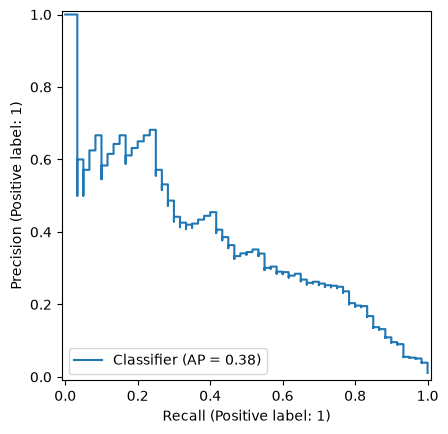

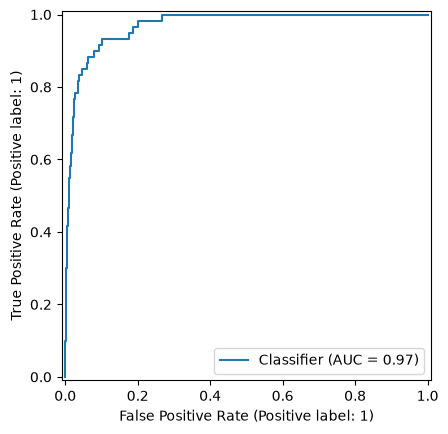

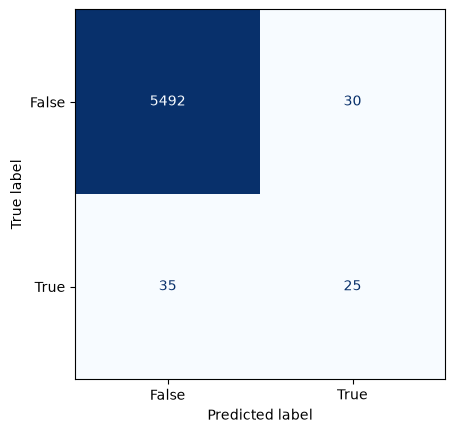

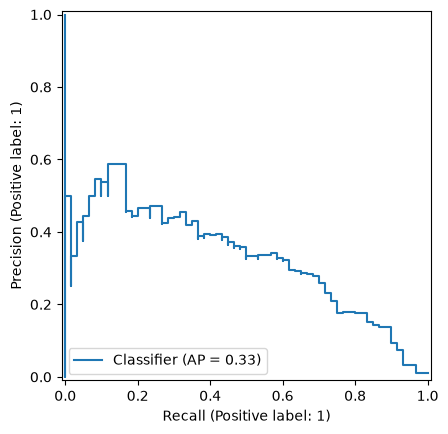

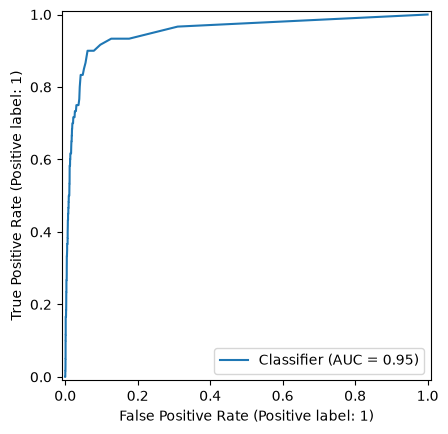

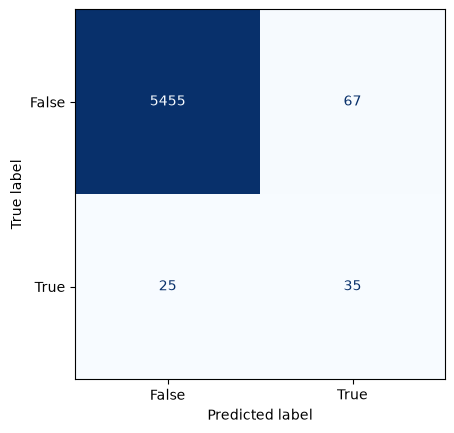

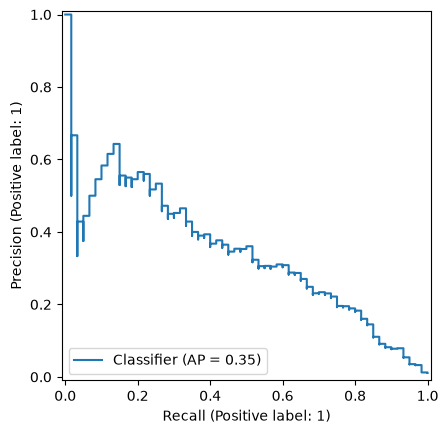

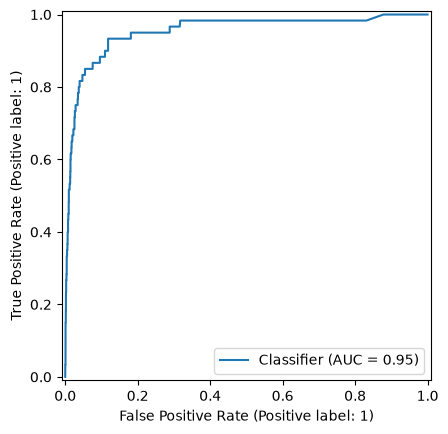

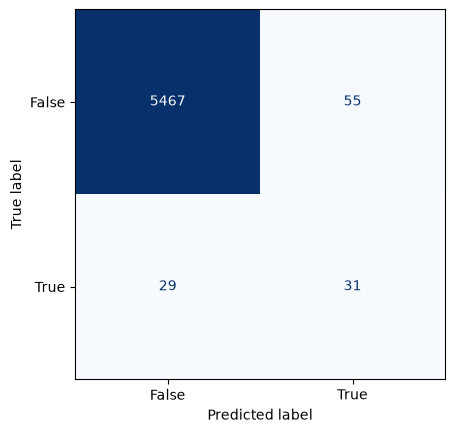

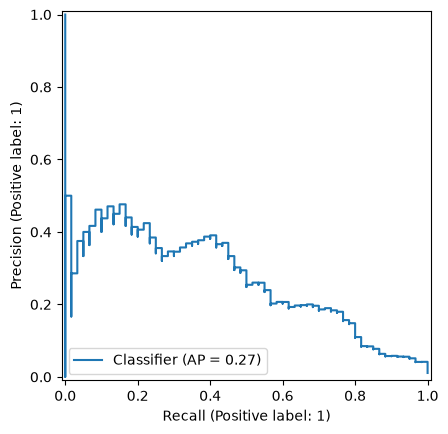

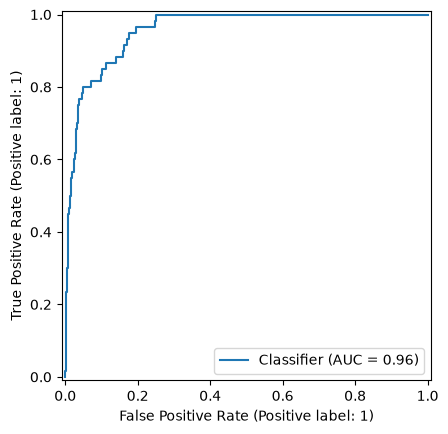

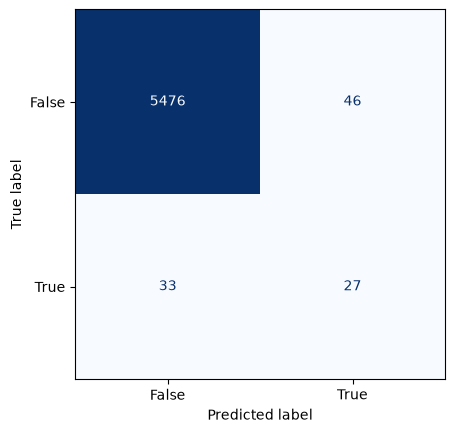

In [12]:
#plotting evaluation
for model_name in models.keys():
    print(model_name)
    precision, recall, thresholds = precision_recall_curve(y_test, models_predictions[model_name])

    # Calculate F1-score for each threshold
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    # Find the optimal threshold
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    print("Best threshold:", best_threshold)
    print("Best F1-score:", f1_scores[best_idx])
    y_pred = (models_predictions[model_name] >= best_threshold).astype(int)
    
    plot_precision_recall_curve(y_test, models_predictions[model_name])
    plot_roc_curve(y_test, models_predictions[model_name])
    plot_confusion_matrix(y_test, y_pred)

In [ ]:
#plotting evaluation
for model_name in models.keys():
    print(model_name)
    precision, recall, thresholds = precision_recall_curve(y_test, models_predictions[model_name])

    # Calculate F1-score for each threshold
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    # Find the optimal threshold
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    print("Best threshold:", best_threshold)
    print("Best F1-score:", f1_scores[best_idx])
    y_pred = (models_predictions[model_name] >= best_threshold).astype(int)
    
    plot_precision_recall_curve(y_test, models_predictions[model_name])
    plot_roc_curve(y_test, models_predictions[model_name])
    plot_confusion_matrix(y_test, y_pred)